# 🔎 Notebook 01 — EDA, Feature Engineering & Threat Modelling

Companion notebook to the **AI-Powered Cybersecurity Threat Detection System**.
The production code lives in `src/`; this notebook is the *walkthrough* version — same steps,
slower pace, with commentary after each cell.

**Run order:** `python main.py download` first (fetches NSL-KDD into `data/raw/`).

## Contents
1. Load & inspect the dataset
2. Exploratory data analysis (class imbalance, attack types, protocol mix)
3. Feature engineering — 13 security-domain features
4. Preprocessing pipeline (OneHot + scaler) and split
5. Train: Logistic Regression baseline → Random Forest → Isolation Forest
6. Evaluation: precision / recall / F1 / FPR, confusion matrices
7. Anomaly-score separation
8. Score a simulated attack burst end-to-end
9. Takeaways


In [1]:
import sys, warnings
sys.path.append('..')          # when running from notebooks/
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='darkgrid')
from src.data_loader import load_nsl_kdd, dataset_summary, print_summary
from src.feature_engineering import add_engineered_features, ENGINEERED_FEATURES
from src.config import ATTACK_CLASSES
pd.set_option('display.max_columns', 60)


## 1. Load & inspect

Each row is **one network connection** described by 41 features. The label is `normal` or one of 24 attack names.
We group those 24 names into the 4 industry families: **DoS, Probe, R2L, U2R**.


In [2]:
df = load_nsl_kdd('train')
print_summary(dataset_summary(df, 'KDDTrain+'))
df.head(3)


  DATASET SUMMARY - KDDTrain+
  Rows / Columns      : 125,973 / 45
  Normal / Attack     : 67,343 / 58,630
  Attack ratio        : 46.54%
  Missing values      : 0
  Duplicate rows      : 0
  Attack families     :
      Normal     67,343
      DoS        45,927
      Probe      11,656
      R2L           995
      U2R            52
  Top attack types    :
      neptune            41,214
      satan               3,633
      ipsweep             3,599
      portsweep           2,931
      smurf               2,646
      nmap                1,493
      back                  956
      teardrop              892
      warezclient           890
      pod                   201

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty,attack_category,is_attack
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.0,150,25,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20,Normal,0
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.0,255,1,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15,Normal,0
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.0,255,26,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19,DoS,1


> **Checkpoint:** 125,973 rows · 0 missing values. If `FileNotFoundError` appears, run `python main.py download`.


## 2. Exploratory data analysis


<Axes: title={'center': 'Protocol mix'}>

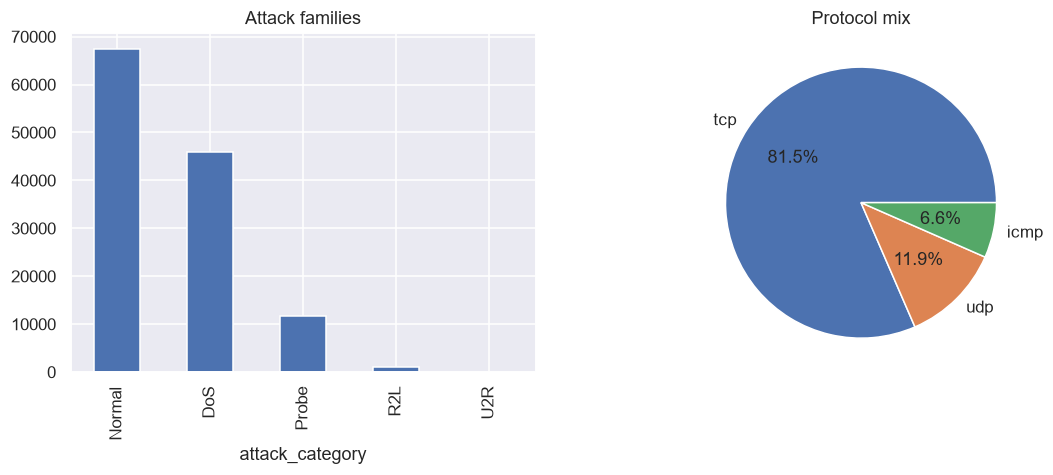

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
df['attack_category'].value_counts().reindex(ATTACK_CLASSES).plot.bar(ax=ax[0], title='Attack families')
df['protocol_type'].value_counts().plot.pie(ax=ax[1], autopct='%1.1f%%', title='Protocol mix');


**Observation:** the data is heavily imbalanced — DoS dominates attacks while **U2R has only 52 samples (0.04%)**.
This is why accuracy alone is misleading here, and why we evaluate per-class recall and use class weights.


Text(0.5, 1.0, 'Top attack types')

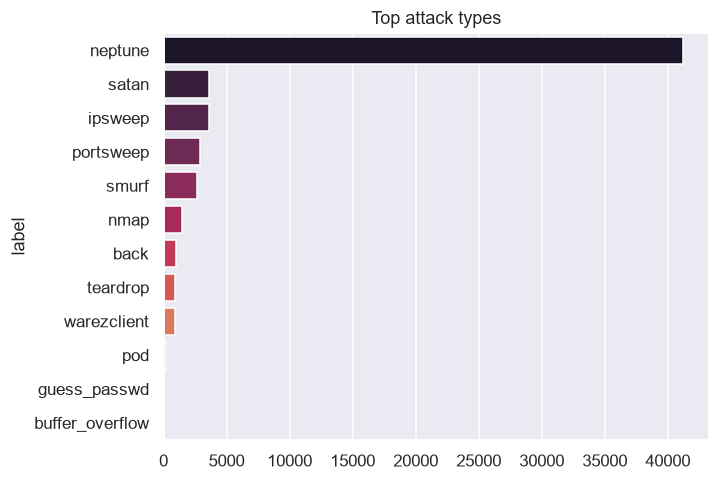

In [4]:
top = df.loc[df.is_attack==1,'label'].value_counts().head(12)
sns.barplot(x=top.values, y=top.index, palette='rocket'); plt.title('Top attack types');


## 3. Feature engineering — turning counters into security signals

Raw counters are hard for a model to combine. We add 13 features that encode **what an analyst looks for**:

| Feature | Security meaning |
|---|---|
| `total_bytes`, `bytes_ratio`, `byte_asymmetry` | exfiltration / direction imbalance |
| `dos_intensity` | error rate × packet count → flood fingerprint |
| `host_scan_ratio`, `traffic_entropy`, `service_concentration` | scan fan-out across hosts/services |
| `login_anomaly`, `critical_service` | credential attacks on ssh/ftp/telnet |
| `privilege_score` | root shell / su / compromised objects → U2R |
| `payload_per_packet` | data-dump behaviour |
| `error_flag_count`, `is_wellknown_port` | malformed packets, targeted services |


In [5]:
rich = add_engineered_features(df)
rich.groupby('attack_category')[['dos_intensity','host_scan_ratio','login_anomaly','privilege_score','bytes_ratio']].mean().round(3)


,dos_intensity,host_scan_ratio,login_anomaly,privilege_score,bytes_ratio
attack_category,,,,,
DoS,155.259,40.269,0.000,0.019,6.028480e+07
Normal,0.202,8.316,0.001,1.097,8.783507e+09
Probe,71.363,104.063,0.000,0.003,3.856781e+11
R2L,0.101,4.632,0.052,0.235,3.073499e+11
U2R,4.503,29.984,0.019,3.423,6.923080e+05


**Read the table:** DoS has by far the highest `dos_intensity`; R2L and U2R light up `login_anomaly` and
`privilege_score`. These features are computed only from the 41 inputs — **no label leakage**.


## 4. Preprocessing & split

`prepare_training_data()` cleans the data, fits the `ColumnTransformer` (OneHot for categoricals,
StandardScaler for numerics) **on the training split only**, and saves it for inference reuse.


In [6]:
from src.preprocess import prepare_training_data
X_train, X_test, y_train, y_test, feature_names, preprocessor, df_rich = prepare_training_data('train')
print('train:', X_train.shape, ' test:', X_test.shape, ' classes:', dict(y_train.value_counts()))


[OK] Preprocessor saved -> C:\Users\Rohit Singh\OneDrive\Desktop\IITD PROJECTS\New folder\AI-Cybersecurity-Threat-Detection\models\preprocessor.joblib
[OK] Encoded feature matrix: 125,973 rows x 135 features
[OK] Cleaning report: {'rows_in': 125973, 'rows_out': 125973, 'missing_filled': 0, 'duplicates_removed': 0}
train: (100778, 135)  test: (25195, 135)  classes: {'Normal': np.int64(53874), 'DoS': np.int64(36741), 'Probe': np.int64(9325), 'R2L': np.int64(796), 'U2R': np.int64(42)}

## 5. Training the three-layer stack

* **Layer 1 — RandomForest**: supervised 5-class classifier.
* **Layer 2 — IsolationForest**: trained on **normal flows only** — it learns what normal looks like,
  so it can flag attack types the classifier has never seen. Alert threshold = p99 of normal scores.
* **Baseline — LogisticRegression**: proves the extra complexity of RF is justified.


In [7]:
from src.train import train_classifier, train_anomaly_detector
rf = train_classifier(X_train, y_train, 'rf')
iso = train_anomaly_detector(X_train, y_train)          # normal-only fit + calibrated threshold
lr = train_classifier(X_train, y_train, 'lr')           # ~70s — safe to skip if in a hurry


[OK] RF trained on 100,778 samples in 11.4s
[OK] IsolationForest trained on 53,874 NORMAL flows in 4.4s
[OK] Live alert threshold = 0.5441 (p99 of normal scores)
[OK] LR trained on 100,778 samples in 592.9s

## 6. Evaluation — the numbers that matter in security

* **Recall** = of all real attacks, how many did we catch? (a miss is a breach)
* **Precision** = of everything we flagged, how much was real? (low = alert fatigue)
* **FPR** = how often we annoy the analyst about benign traffic.


In [8]:
from src.evaluate import evaluate_classifier, evaluate_anomaly_detector
for name, model in [('RandomForest', rf), ('LogisticRegression', lr)]:
    r = evaluate_classifier(model, X_test, y_test, name)
    print(f"{name:20} acc={r['accuracy']:.4f} P={r['precision']:.4f} R={r['recall']:.4f} F1={r['f1_score']:.4f} FPR={r['false_positive_rate']:.4f}")
r_iso = evaluate_anomaly_detector(iso, X_test, y_test)
print(f"{'IsolationForest':20} acc={r_iso['accuracy']:.4f} P={r_iso['precision']:.4f} R={r_iso['recall']:.4f} F1={r_iso['f1_score']:.4f}")


RandomForest         acc=0.9986 P=0.9995 R=0.9974 F1=0.9985 FPR=0.0004
LogisticRegression   acc=0.9692 P=0.9408 R=0.9967 F1=0.9679 FPR=0.0546
IsolationForest      acc=0.9010 P=0.9847 R=0.7998 F1=0.8826

In [9]:
# per-class quality — where does the model actually fail?
from sklearn.metrics import classification_report
print(classification_report(y_test, rf.predict(X_test), digits=3))


              precision    recall  f1-score   support

         DoS      1.000     1.000     1.000      9186
      Normal      0.998     1.000     0.999     13469
       Probe      1.000     0.991     0.995      2331
         R2L      1.000     0.985     0.992       199
         U2R      0.750     0.600     0.667        10

    accuracy                          0.999     25195
   macro avg      0.949     0.915     0.931     25195
weighted avg      0.999     0.999     0.999     25195


**Honest reading:** DoS/Probe are near-perfect; R2L is strong; **U2R recall is the weak spot** — only 10 test samples.
That's exactly why the rule layer exists (e.g. `root_shell == 1` fires deterministically).


Text(0.5, 1.0, 'RandomForest — hold-out')

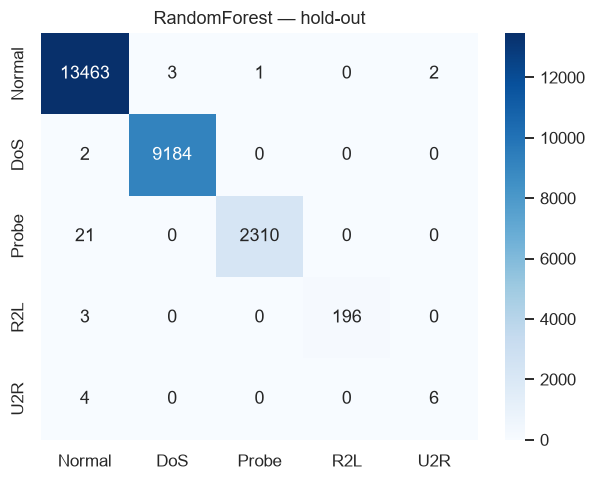

In [10]:
from sklearn.metrics import confusion_matrix
sns.heatmap(confusion_matrix(y_test, rf.predict(X_test), labels=ATTACK_CLASSES), annot=True, fmt='d',
            xticklabels=ATTACK_CLASSES, yticklabels=ATTACK_CLASSES, cmap='Blues'); plt.title('RandomForest — hold-out');


## 7. Anomaly-score separation (the zero-day safety net)


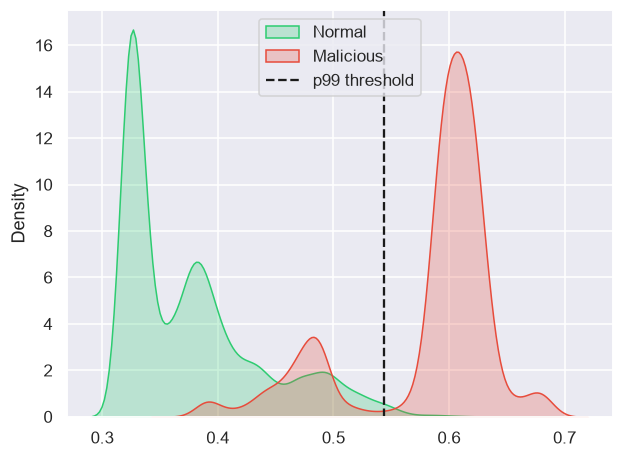

In [11]:
score = -iso.score_samples(X_test); truth = (y_test!='Normal').values
sns.kdeplot(x=score[~truth], fill=True, label='Normal', color='#2ecc71')
sns.kdeplot(x=score[truth],  fill=True, label='Malicious', color='#e74c3c')
plt.axvline(getattr(iso,'alert_threshold_'), ls='--', color='k', label='p99 threshold'); plt.legend();


## 8. End-to-end: score a simulated attack burst

Now the fun part — generate a mixed traffic capture with the virtual cyber range, run it through the
**full detection engine** (ML + anomaly + rules + risk fusion) and measure against ground truth.


In [12]:
from src.simulate import TrafficSimulator
from src.detect import ThreatDetector
sim = TrafficSimulator(seed=42).simulate(n_events=800, attack_rate=0.20, seed=42)
det = ThreatDetector()
scored = det.predict(sim['traffic'])
alerts = ThreatDetector.build_alerts(scored, src_ips=sim['traffic']['src_ip'],
                                    dst_ips=sim['traffic']['dst_ip'], services=sim['traffic']['service'])
print(f'{len(alerts)} alerts from {len(scored)} flows')
alerts[['timestamp','severity','threat_class','src_ip','dst_ip','service','risk_score','reason']].head(6)


[SIM] Generated 800 events (160 malicious / 640 benign) across 10 scenarios
206 alerts from 800 flows

,timestamp,severity,threat_class,src_ip,dst_ip,service,risk_score,reason
0,2026-10-15 19:46:45,MEDIUM,Probe,172.16.0.187,10.0.3.14,private,100.00,Elevated rejection rate (0.70); Sweeping many ...
1,2026-10-15 19:46:46,HIGH,Unknown-Anomaly,192.168.1.38,10.0.0.20,ssh,70.86,Brute-force pattern: 6 failed logins; Access t...
2,2026-10-15 19:46:48,MEDIUM,Probe,172.16.0.250,10.0.2.7,private,100.00,Elevated rejection rate (0.70); Sweeping many ...
3,2026-10-15 19:46:49,HIGH,DoS,192.168.1.47,10.0.5.9,http,100.00,SYN-flood signature: serror_rate=1.00 over 511...
4,2026-10-15 19:46:51,HIGH,Unknown-Anomaly,172.16.0.25,10.0.4.22,eco_i,58.03,ICMP sweep/flood: 200 echo requests in one bur...
5,2026-10-15 19:46:52,HIGH,DoS,203.0.113.214,10.0.4.22,http,100.00,SYN-flood signature: serror_rate=1.00 over 511...


In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score
y, p = sim['traffic']['is_attack_truth'], scored['is_attack']
print(f'LIVE  precision={precision_score(y,p):.3f}  recall={recall_score(y,p):.3f}  f1={f1_score(y,p):.3f}')
print()
scored['scenario'] = sim['traffic']['scenario'].values
scored['truth'] = y.values
print(scored[scored.truth==1].groupby('scenario')['is_attack'].mean().mul(100).round(1).to_string())


LIVE  precision=0.913  recall=1.000  f1=0.954

scenario
Data Exfiltration Burst (U2R)          100.0
FTP Password Guessing (R2L)            100.0
HTTP Flood / CC Attack (DoS)           100.0
Local Privilege Escalation (U2R)       100.0
Ping Sweep / Host Discovery (Probe)    100.0
SSH Brute Force (R2L)                  100.0
SYN Flood (DoS)                        100.0
Stealth Port Scan (Probe)              100.0
Web App Probe / Injection (R2L)        100.0

## 9. Takeaways

1. **Imbalance is the core challenge** — evaluate per class, weight the majority down, and never trust raw accuracy.
2. **Domain features win** — several engineered features land in the model's top-20 by importance.
3. **One model is not a system** — supervised + unsupervised + rules covers different failure modes.
4. **Measure against ground truth** — the cyber range labels every flow, so precision/recall are real numbers, not vibes.
5. **Report the hard number too** — the official `KDDTest+` split (17 unseen attack types) is the honest generalisation test.

→ Production code: `src/` · Live console: `python main.py dashboard` · Docs: `docs/`
